In [5]:
import sys
from pathlib import Path
sys.path[:0] = [str(Path.cwd().parent)]

import numpy as np
import matplotlib.pyplot as plt

from scripts.Hamiltonian import Hamiltonian
from scripts.Lattice import Lattice
from scripts.partial_sc import partial_sc
from scripts.self_consistency_ft.self_consistency_k import bdg_sc_full_k

In [ ]:
V_prime_arr = np.linspace(0.75, 1, 25)

# V_prime_arr = np.linspace(0.0, 0.42105263, 8)
sfpfs_arr = np.zeros_like(V_prime_arr)
dfpfd_arr = np.zeros_like(V_prime_arr)
d_arr = np.zeros_like(V_prime_arr)
s_arr = np.zeros_like(V_prime_arr)

T = 1e-5

# BULK

In [ ]:
t = 1.0
mu = 1.8 * t

U = 0.0
V_prime = 0.0

# Lattice parameters
Nx, Ny = 100, 100

# Tolerances and maximum iterations for self-consistency
atol = 1e-6
rtol = 1e-3
maxiter = 1000

for i, val in enumerate(V_prime_arr):
    out = bdg_sc_full_k(
        t, mu, temperature=T,
        V=val, Nx=Nx, Ny=Ny,
        atol=atol, rtol=rtol,
        maxiter=maxiter,
        F_init=[0.01, -0.01, 0.01j, -0.01j]
    )
    d_arr[i] = 50 * np.real(out.F_px)
    s_arr[i] = 10 * np.real(out.F_px)
    print("V':", val, "p-wave", np.real(out.F_px), "s-wave:", s_arr[i], "d-wave:", d_arr[i])

V': 0.8 p-wave 7.149249588414015e-15 s-wave: 7.149249588414015e-14 d-wave: 3.5746247942070077e-13
V': 0.8078947368421053 p-wave 7.574703145852835e-15 s-wave: 7.574703145852836e-14 d-wave: 3.7873515729264177e-13


In [ ]:
print("s-wave:", s_arr)
print("d-wave:", d_arr)

s-wave: [0.00000000e+00 1.93307843e-16 8.19406504e-16 3.19000434e-15
 2.67572160e-15 5.23292956e-15 8.42608892e-15 1.42376209e-14
 2.67605166e-14 4.26950499e-14 1.05660918e-13 9.05614085e-03
 3.14670211e-02 4.88679129e-02 6.77375552e-02 8.99293702e-02
 1.16309296e-01 1.47101530e-01 1.81599097e-01 2.18943229e-01
 2.58379492e-01 2.99387070e-01 3.41533075e-01 3.84479340e-01
 4.27899605e-01]
d-wave: [0.00000000e+00 9.66539213e-16 4.09703252e-15 1.59500217e-14
 1.33786080e-14 2.61646478e-14 4.21304446e-14 7.11881047e-14
 1.33802583e-13 2.13475250e-13 5.28304588e-13 4.52807043e-02
 1.57335105e-01 2.44339565e-01 3.38687776e-01 4.49646851e-01
 5.81546481e-01 7.35507649e-01 9.07995484e-01 1.09471614e+00
 1.29189746e+00 1.49693535e+00 1.70766538e+00 1.92239670e+00
 2.13949802e+00]


# SFPFS

In [ ]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t
muN = 1.2 * t
mu = np.zeros(lattice.X)
mu[:widthD] = muN
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muN

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


V = None

U0 = 1 * t
U = U0 * np.ones(lattice.X)
U[widthD:-widthD] = 0
U[widthD-1] = U0/2
U[-widthD] = U0/2

for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F0_init=s_arr[i],
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F0"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=1e-6, rtol=1e-3, maxiter=500)
    F, Fuu, Fdd = H.get_correlations()
    sfpfs_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("sfpfs_arr:", sfpfs_arr)

Converged after 1 iterations
Converged after 12 iterations
Converged after 16 iterations


# DFPFD


In [ ]:
widthD = 10
widthF = 1
widthP = 40

X, Y = widthD+widthF+widthP+widthF+widthD, 200
lattice = Lattice(X, Y)

t = 1

muD = 0.0 * t
muP = 1.8 * t
muF = 1.4 * t

mu = np.zeros(lattice.X)
mu[:widthD] = muD
mu[widthD:widthD + widthF] = muF
mu[widthD + widthF:widthD + widthF + widthP] = muP
mu[widthD + widthF + widthP:widthD + widthF + widthP + widthF] = muF
mu[widthD + widthF + widthP + widthF:widthD + widthF + widthP + widthF + widthD] = muD

h0 = 0.9 * t
h = np.zeros_like(mu)
h[widthD:widthD + widthF] = h0
h[widthD + widthF + widthP + widthF-1] = -h0


U0 = 0.0 * t
U = U0 * np.ones(lattice.X)
U[widthD:] = 0
U[widthD-1] = U0/2

V0 = 1 * t
V = V0 * np.ones(lattice.X)
V[widthD:-widthD] = 0
V[widthD-1] = V0/2
V[-widthD] = V0/2


for i, val in enumerate(V_prime_arr):
    V_prime0 = val * t
    V_prime = V_prime0 * np.ones(lattice.X)
    V_prime[:widthF+widthD] = 0
    V_prime[widthF+widthD+widthP:] = 0
    V_prime[widthF+widthD] = V_prime0/2
    V_prime[widthF+widthD+widthP-1] = V_prime0/2

    H = Hamiltonian(t, mu, lattice, U=U, V_prime=V_prime, V=V,
                    F_init=[d_arr[i], d_arr[i], -d_arr[i], -d_arr[i]],
                    Fuu_init=[0.01, -0.01, 0.01j, -0.01j],
                    Fdd_init=[0.01, -0.01, 0.01j, -0.01j],
                    hx=h)

    fixed_sites = (V_prime == 0)
    fixed_syms = ["F_xplus", "F_xmin", "F_yplus", "F_ymin"]
    partial_sc(H, temperature=T,
            fixed_sites=fixed_sites,
            fixed_syms=fixed_syms,
            atol=1e-6, rtol=1e-3, maxiter=500)
    F, Fuu, Fdd = H.get_correlations()
    dfpfd_arr[i] = np.real(Fuu.px-Fdd.px)[int(widthD+widthF+widthP/2)-1]/2
print("dfpfd_arr:", dfpfd_arr)

In [ ]:
np.savez(
    f"zoomin_data.npz",
    V_prime_arr=V_prime_arr,
    bulk = s_arr/10,
    sfpfs_arr=sfpfs_arr,
    dfpfd_arr=dfpfd_arr
)

In [ ]:
data1 = np.load("zoomin_data.npz")

V_prime_arr = data1['V_prime_arr']
bulk = data1['bulk']
nfpfn_arr = data1['nfpfn_arr']
sfpfs_arr = data1['sfpfs_arr']
dfpfd_arr = data1['dfpfd_arr']

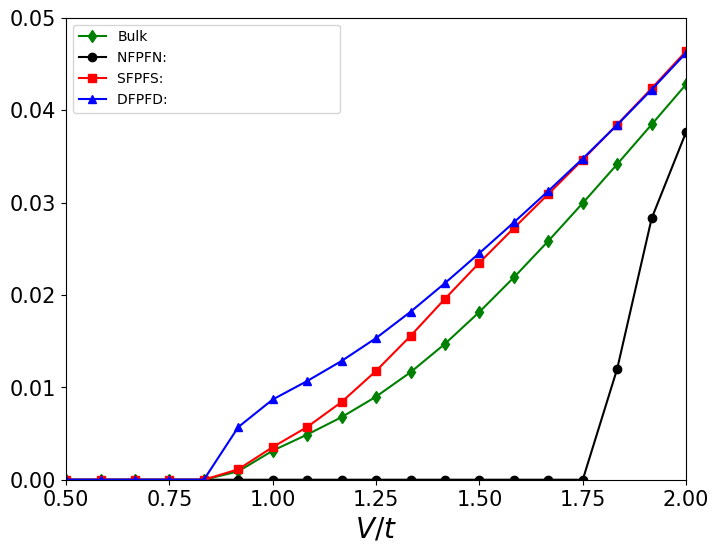

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(V_prime_arr, bulk, '-d', label="Bulk", color='green')
plt.plot(V_prime_arr, np.zeros_like(V_prime_arr), '-o', label="NFPFN:                                      ", color='black')
plt.plot(V_prime_arr, sfpfs_arr, '-s', label="SFPFS:                                      ", color='red')
plt.plot(V_prime_arr, dfpfd_arr, '-^', label="DFPFD:                                      ", color='blue')
# plt.xlim(0.5, 2)
plt.ylim(0, 0.05)
# plt.xticks(np.arange(0.5, 2.1, 0.25),fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel(r"$V/t$", fontsize=20)
plt.legend()
plt.savefig("px_of_V_prime.svg")

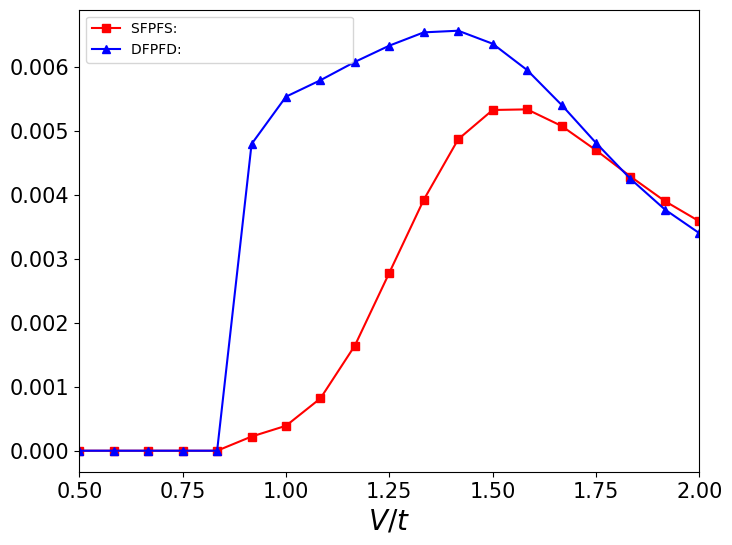

In [ ]:
plt.figure(figsize=(8, 6))
plt.plot(V_prime_arr, sfpfs_arr-bulk, '-s', label="SFPFS:                                      ", color='red')
plt.plot(V_prime_arr, dfpfd_arr-bulk, '-^', label="DFPFD:                                      ", color='blue')
# plt.xlim(0.5, 2)
# plt.xticks(np.arange(0.5, 2.1, 0.25),fontsize=15)
plt.yticks(fontsize=15)
plt.xlabel(r"$V/t$", fontsize=20)
plt.legend()
plt.savefig("px_of_V_prime.svg")